In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

from gensim.models import Word2Vec

%matplotlib inline
pd.set_option("display.max_colwidth", 100)
RANDOM_STATE = 42


## Preparar os dados

Usei o `data/processed/reviews_clean.csv`.
Trabalhei com os dados em inglês (maior volume), removendo reviews vazias e o
excesso de texto exatamente duplicado.


In [2]:
df = pd.read_csv("../data/processed/reviews_clean.csv")

en = df[(df["language"] == "english") & (~df["is_empty"])].copy()
en = en[~en["is_duplicate_text"] | ~en["clean_text"].duplicated(keep="first")]
en = en[en["tokens_no_stopwords"].notna() & (en["tokens_no_stopwords"] != "")]

DOMAIN_STOPWORDS = {
    "game", "games", "play", "playing", "played", "cs2", "cs",
    "valve", "steam", "im", "ive",
}
def strip_domain_stopwords(text: str) -> str:
    return " ".join(w for w in str(text).split() if w not in DOMAIN_STOPWORDS)

en["text_domain"] = en["tokens_no_stopwords"].apply(strip_domain_stopwords)
en = en[en["text_domain"].str.strip() != ""].reset_index(drop=True)

print(f"Reviews utilizadas: {len(en)}")
en[["game_name", "voted_up", "clean_text"]].head(3)


Reviews utilizadas: 1494


,game_name,voted_up,clean_text
0,Counter-Strike 2,True,would be pro if it werent laggy asf. stupid jitter ms
1,Counter-Strike 2,True,w game im gay and from israel
2,Counter-Strike 2,True,this is valoront for big boys


## Construir as três representações

### BoW e TF-IDF



In [3]:
bow_vectorizer = CountVectorizer(max_features=3000, min_df=3, max_df=0.85)
X_bow = bow_vectorizer.fit_transform(en["text_domain"])

tfidf_vectorizer = TfidfVectorizer(max_features=3000, min_df=3, max_df=0.85)
X_tfidf = tfidf_vectorizer.fit_transform(en["text_domain"])

print(f"BoW    : {X_bow.shape}")
print(f"TF-IDF : {X_tfidf.shape}")


BoW    : (1494, 1091)
TF-IDF : (1494, 1091)


###  Word2Vec

Seguindo o exemplo da Aula 7: treinei um modelo Word2Vec (Skip-gram) pequeno com o
próprio corpus, depois representei cada review pela média dos vetores das suas
palavras.


In [4]:
tokens_para_w2v = en["text_domain"].str.split().tolist()

modelo_w2v = Word2Vec(
    sentences=tokens_para_w2v,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    seed=RANDOM_STATE,
    workers=1,
    epochs=100,
)

print("Tamanho do vocabulário:", len(modelo_w2v.wv))

def vetor_documento_w2v(tokens):
    vetores = [modelo_w2v.wv[t] for t in tokens if t in modelo_w2v.wv]
    if not vetores:
        return np.zeros(modelo_w2v.vector_size, dtype=np.float32)
    return np.mean(vetores, axis=0)

X_w2v = np.vstack([vetor_documento_w2v(t) for t in tokens_para_w2v])
print("Matriz Word2Vec:", X_w2v.shape)


Tamanho do vocabulário: 1848
Matriz Word2Vec: (1494, 100)


## Clusterização + PCA (resposta à pergunta 2)

Rodei o mesmo K-Means (K=6) nas três representações e comparei o silhouette
score (separação dos clusters) e a leitura dos termos/exemplos de cada grupo.


In [5]:
K = 6
resultados_cluster = {}

for nome, X in [("BoW", X_bow), ("TF-IDF", X_tfidf), ("Word2Vec", X_w2v)]:
    km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels)
    resultados_cluster[nome] = {"km": km, "labels": labels, "silhouette": score, "X": X}
    print(f"{nome:10s} silhouette={score:.3f}")


BoW        silhouette=0.752


TF-IDF     silhouette=0.072


Word2Vec   silhouette=0.014


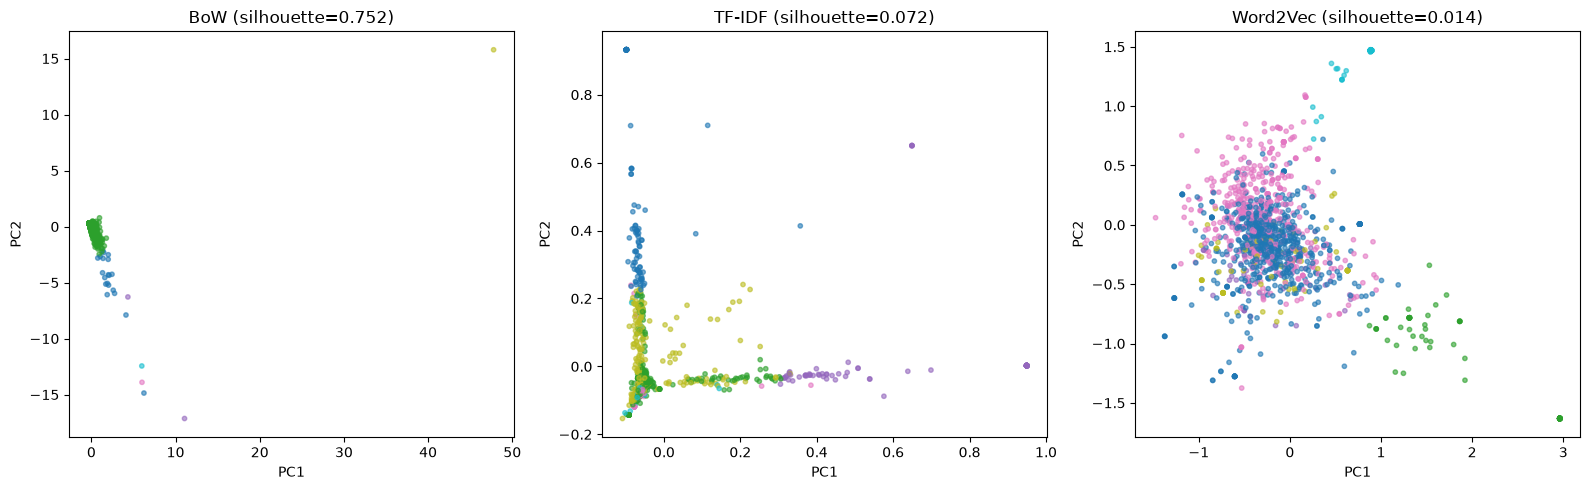

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (nome, res) in zip(axes, resultados_cluster.items()):
    X_denso = res["X"].toarray() if hasattr(res["X"], "toarray") else res["X"]
    coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_denso)
    ax.scatter(coords[:, 0], coords[:, 1], c=res["labels"], cmap="tab10", s=10, alpha=0.6)
    ax.set_title(f"{nome} (silhouette={res['silhouette']:.3f})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.savefig("figuras_clustering_comparacao.png", dpi=120)
plt.show()


In [7]:
# Ler alguns exemplos de cada cluster da representação com melhor silhouette
melhor = max(resultados_cluster, key=lambda n: resultados_cluster[n]["silhouette"])
print(f"Representação com melhor silhouette: {melhor}\n")

labels_melhor = resultados_cluster[melhor]["labels"]
en_tmp = en.assign(cluster=labels_melhor)
for c in sorted(en_tmp["cluster"].unique()):
    sub = en_tmp[en_tmp["cluster"] == c]
    print(f"--- Cluster {c} (n={len(sub)}) ---")
    for txt in sub["clean_text"].head(2):
        print("  -", txt[:80])


Representação com melhor silhouette: BoW

--- Cluster 0 (n=20) ---
  - The cheating problem in CS2 is completely out of control right now. It genuinely
  - A game I've been playing for more years than I can remember ❤️ I’ve been playing
--- Cluster 1 (n=1469) ---
  - would be pro if it werent laggy asf. stupid jitter ms
  - w game im gay and from israel
--- Cluster 2 (n=2) ---
  - Epic games killed a great game with strong roots by refusing to improve servers,
  - Rocket League is one of a kind, like no other. When we say Rocket League , peopl
--- Cluster 3 (n=1) ---
  - Verdict ✅ Recommended One of the best co-op games on the market, and a great cho
--- Cluster 4 (n=1) ---
  - Party rock Yeah Woo! Let's go! Party rock is in the house tonight Everybody just
--- Cluster 5 (n=1) ---
  - Title: A Monument to Institutional Malice, Toxic Incompetence, and Betrayed Devo


Olhando só o número, o BoW parece o melhor (silhouette bem mais alto), mas o tamanho dos clusters mostra outra coisa: quase todas as reviews caíram num cluster só, e o resto são 1-2 documentos isolados, um artefato de contagens não normalizadas, não uma separação real por assunto. TF-IDF e Word2Vec ficaram bem mais equilibrados.

## Busca e recomendação

Mesma consulta, buscada nos espaços TF-IDF e Word2Vec, comparando os top-5 documentos
retornados em cada um. BoW foi deixado de fora da busca, ele não pondera por raridade, então tende a performar pior nessa tarefa.


In [8]:
def buscar_tfidf(consulta, k=5):
    vetor = strip_domain_stopwords(consulta.lower())
    vetor_tfidf = tfidf_vectorizer.transform([vetor])
    sims = cosine_similarity(vetor_tfidf, X_tfidf).flatten()
    idx = sims.argsort()[::-1][:k]
    return pd.DataFrame({"similaridade": sims[idx], "review": en["clean_text"].iloc[idx].values})

def buscar_w2v(consulta, k=5):
    tokens = strip_domain_stopwords(consulta.lower()).split()
    vetor = vetor_documento_w2v(tokens)
    sims = cosine_similarity(vetor.reshape(1, -1), X_w2v).flatten()
    idx = sims.argsort()[::-1][:k]
    return pd.DataFrame({"similaridade": sims[idx], "review": en["clean_text"].iloc[idx].values})

consulta = "too many cheaters and hackers ruining the game"

print("=== TF-IDF ===")
display(buscar_tfidf(consulta))
print("\n=== Word2Vec ===")
display(buscar_w2v(consulta))


=== TF-IDF ===


,similaridade,review
0,0.573606,too many cheaters
1,0.573606,to many cheaters
2,0.573606,Too many cheaters in this game
3,0.573606,So many cheaters jfc
4,0.462260,i dislike how many bots there are and hackers and i like how fun the game is



=== Word2Vec ===


,similaridade,review
0,0.934308,to many cheaters
1,0.934308,Too many cheaters in this game
2,0.934308,So many cheaters jfc
3,0.934308,too many cheaters
4,0.932704,filled with too many cheaters


Os top-5 de TF-IDF e Word2Vec trazem, na maioria, variações quase idênticas da mesma frase sobre cheaters,
 um sinal de que a base tem bastante texto quase-duplicado que a deduplicação exata não capturou.

## Classificação

Alvo: `voted_up` (recomendação positiva/negativa), já vem pronto nos dados, sem
precisar anotar nada.


In [9]:
y = en["voted_up"].astype(str)
print(y.value_counts(normalize=True).round(2))

idx_train, idx_test = train_test_split(
    en.index, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]


voted_up
True     0.85
False    0.15
Name: proportion, dtype: float64


In [10]:
def avaliar_classificador(nome, X):
    X_train, X_test = X[en.index.get_indexer(idx_train)], X[en.index.get_indexer(idx_test)]
    clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced")
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"\n=== {nome} ===")
    print(f"Acurácia: {acc:.3f}")
    print(classification_report(y_test, y_pred, digits=3))
    return clf, acc

resultados_clf = {}
resultados_clf["BoW"] = avaliar_classificador("BoW", X_bow)
resultados_clf["TF-IDF"] = avaliar_classificador("TF-IDF", X_tfidf)
resultados_clf["Word2Vec"] = avaliar_classificador("Word2Vec", X_w2v)



=== BoW ===
Acurácia: 0.873
              precision    recall  f1-score   support

       False      0.568     0.568     0.568        44
        True      0.925     0.925     0.925       255

    accuracy                          0.873       299
   macro avg      0.747     0.747     0.747       299
weighted avg      0.873     0.873     0.873       299


=== TF-IDF ===
Acurácia: 0.870
              precision    recall  f1-score   support

       False      0.556     0.568     0.562        44
        True      0.925     0.922     0.923       255

    accuracy                          0.870       299
   macro avg      0.740     0.745     0.743       299
weighted avg      0.871     0.870     0.870       299


=== Word2Vec ===
Acurácia: 0.779
              precision    recall  f1-score   support

       False      0.359     0.636     0.459        44
        True      0.928     0.804     0.861       255

    accuracy                          0.779       299
   macro avg      0.643     0.720

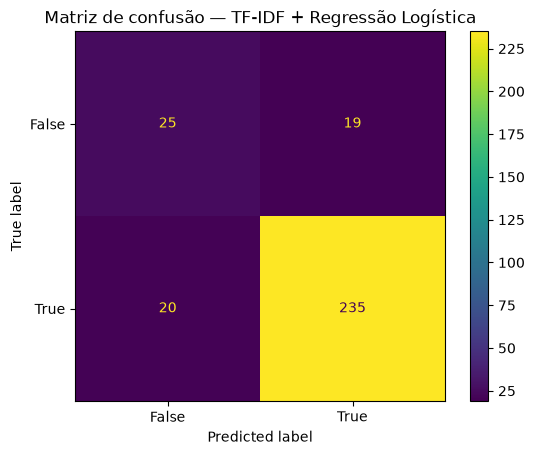

In [11]:
clf_tfidf, _ = resultados_clf["TF-IDF"]
ConfusionMatrixDisplay.from_estimator(
    clf_tfidf, X_tfidf[en.index.get_indexer(idx_test)], y_test
)
plt.title("Matriz de confusão — TF-IDF + Regressão Logística")
plt.savefig("figura_matriz_confusao_tfidf.png", dpi=120)
plt.show()


In [12]:
# Testar o classificador (TF-IDF) com frases novas, fora do dataset
novas_reviews = [
    "This game is amazing, best purchase ever!",
    "Full of cheaters, waste of money.",
    "It's okay, nothing special but playable.",
]

vetor_novas = tfidf_vectorizer.transform(novas_reviews)
previsoes = clf_tfidf.predict(vetor_novas)
for texto, pred in zip(novas_reviews, previsoes):
    print(f"[{pred:5s}] {texto}")


[True ] This game is amazing, best purchase ever!
[False] Full of cheaters, waste of money.
[False] It's okay, nothing special but playable.


BoW e TF-IDF ficaram praticamente empatados em acurácia (~0,87), à frente do Word2Vec (~0,78). No teste com frases novas, o classificador acertou as duas frases de polaridade clara e errou a frase neutra.

## Extração de Relações

### Reconhecimento de Entidades Nomeadas (NER)

Teste exploratório com o modelo de inglês do spaCy (`en_core_web_sm`) em algumas reviews reais.


In [13]:
import spacy
nlp_ner = spacy.load("en_core_web_sm")

amostra_ner = en["clean_text"].sample(8, random_state=RANDOM_STATE).tolist()
for texto in amostra_ner:
    doc = nlp_ner(texto)
    ents = [(ent.text, ent.label_) for ent in doc.ents]
    print(f"- {texto[:70]!r} -> {ents if ents else 'nenhuma entidade'}")


- 'video game' -> nenhuma entidade
- "after 1k hours you'll like it" -> [('1k hours', 'TIME')]
- "I've played this game with some of my friends but only finished it wit" -> [('two', 'CARDINAL')]
- 'amoung us in 2020 this game was its lit and very fun but i only play i' -> [('amoung us', 'ORG'), ('2020', 'DATE')]
- 'g' -> nenhuma entidade
- 'fire, lwk addicting.' -> nenhuma entidade
- "9.5/10 game. I know I'm a bit late to review, and people probably won'" -> [('9.5/10', 'CARDINAL'), ('Rune Factory', 'ORG'), ('years', 'DATE'), ('Stardew Valley', 'PERSON'), ('Stardew', 'PERSON'), ('Stardew Valley', 'LOC')]
- 'the game looks fun but its genuine hell to get autopetters whilst bein' -> [('♥♥♥ PIERRE', 'PERSON')]


O NER encontrou poucas entidades relevantes, a maioria das reviews não tem nome de pessoa, lugar ou organização, e algumas das poucas encontradas são falsos positivos.

### Extração de Relações

Não implementei, reviews são maioriA fragmentos sem estrutura completa. Teste rápido abaixo confirma isso.

In [14]:
def extrair_relacao_svo_simples(texto):
    doc = nlp_ner(texto)
    for verbo in doc:
        if verbo.pos_ == "VERB":
            sujeitos = [t for t in verbo.children if t.dep_ in {"nsubj", "nsubj:pass"}]
            objetos = [t for t in verbo.children if t.dep_ in {"obj", "iobj"}]
            if sujeitos and objetos:
                return f"{sujeitos[0].text} -{verbo.lemma_}-> {objetos[0].text}"
    return None

for texto in en["clean_text"].head(10):
    print(f"{texto[:60]!r:65s} -> {extrair_relacao_svo_simples(texto)}")


'would be pro if it werent laggy asf. stupid jitter ms'           -> None
'w game im gay and from israel'                                   -> None
'this is valoront for big boys'                                   -> None
'EZ Game EZ life.'                                                -> None
'best game'                                                       -> None
'its fun'                                                         -> None
"it's ok"                                                         -> None
'good'                                                            -> None
'666 ANOMALY PATTERN 666'                                         -> None
'Full of hackers fix your game, meanwhile play on faceit'         -> None
